All the libraries

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras import layers, models
import tensorflow as tf
import tensorflow_datasets as tfds
from skimage.color import rgb2lab, lab2rgb
import numpy as np
import math
from google.colab import drive
import os
import tensorflow as tf
from tensorflow.keras import layers as KL, models
import torch
import random
from tensorflow.keras import mixed_precision


Seed

In [ ]:
SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
mixed_precision.set_global_policy('mixed_float16')

GPU

In [ ]:
gpu_avail = torch.cuda.is_available()
print(f"Is the GPU available? {gpu_avail}")

device = torch.device("cuda") if torch.cuda.is_available() else torch.device("cpu")
print(f"Device: {device}")

Is the GPU available? True
Device: cuda


Some parameters

In [ ]:
# === CONFIGURATION ===
IMG_SIZE = 128
BATCH_SIZE = 64
# Probabilità di applicare augmentation al campione
AUG_PROB  = 0.0   # DATA AUGMENTATION DISABILITATA
MIN_SCALE = 0.92   # mantieni ≥92% dell'immagine (zoom-in leggero)
BASE = 48

Preprocess image

In [ ]:
def preprocess_image(sample):
    """Resize and normalize image"""
    image = tf.image.resize(sample['image'], (IMG_SIZE, IMG_SIZE))
    image = tf.cast(image, tf.float32) / 255.0
    return image

RGB to LAB and Viceversa

In [ ]:
import numpy as np
import warnings
from skimage.color import lab2rgb, rgb2lab

def lab_batch_to_rgb(L_batch01, ab_batch_norm, clip_lab=True, suppress_warnings=True):
    """
    Converte batch di (L in [0,1], ab in [-1,1]) -> RGB in [0,1].
    L_batch01: (B,H,W,1) float, [0,1]
    ab_batch_norm: (B,H,W,2) float, [-1,1]
    Ritorna: rgb (B,H,W,3) float32, [0,1]
    """
    L_batch01 = np.asarray(L_batch01)
    ab_batch_norm = np.asarray(ab_batch_norm)
    assert L_batch01.ndim == 4 and L_batch01.shape[-1] == 1, "L_batch01 deve essere (B,H,W,1)"
    assert ab_batch_norm.ndim == 4 and ab_batch_norm.shape[-1] == 2, "ab_batch_norm deve essere (B,H,W,2)"
    assert L_batch01.shape[:3] == ab_batch_norm.shape[:3], "L e ab devono avere stessa (B,H,W)"

    B, H, W, _ = L_batch01.shape

    # 1) Denormalizza a range Lab canonico
    L = (L_batch01 * 100.0).astype(np.float64)            # [0,100]
    ab = (ab_batch_norm * 128.0).astype(np.float64)       # circa [-128,128]

    # 2) Clip leggero per stabilità (evita bordi problematici)
    if clip_lab:
        L  = np.clip(L,  0.0 + 1e-6, 100.0 - 1e-6)
        ab = np.clip(ab, -127.0,      127.0)

    lab = np.concatenate([L, ab], axis=-1)                # (B,H,W,3)

    # 3) lab2rgb immagine-per-immagine
    rgb_list = []
    ctx = warnings.catch_warnings()
    if suppress_warnings:
        warnings.simplefilter("ignore")
    with ctx:
        for i in range(B):
            rgb = lab2rgb(lab[i].astype(np.float64))      # (H,W,3) in [0,1] (può leggermente uscire)
            rgb_list.append(rgb)

    rgb = np.stack(rgb_list, axis=0).astype(np.float32)
    rgb = np.clip(rgb, 0.0, 1.0)                          # forza [0,1] pulito
    return rgb


def rgb_batch_to_lab(rgb_batch01, clip_rgb=True, normalize_ab=True, return_L01=True, suppress_warnings=True):
    """
    Converte batch di RGB [0,1] -> (L,ab) in formato del tuo modello.
    rgb_batch01: (B,H,W,3) float, atteso in [0,1]
    Ritorna (L_batch01, ab_batch_norm) se return_L01 & normalize_ab,
            altrimenti ritorna L* in [0,100] e/o a*,b* non normalizzati.
    """
    rgb_batch01 = np.asarray(rgb_batch01)
    assert rgb_batch01.ndim == 4 and rgb_batch01.shape[-1] == 3, "rgb_batch01 deve essere (B,H,W,3)"

    if clip_rgb:
        rgb = np.clip(rgb_batch01, 0.0, 1.0).astype(np.float64)
    else:
        rgb = rgb_batch01.astype(np.float64)

    B = rgb.shape[0]
    lab_list = []
    ctx = warnings.catch_warnings()
    if suppress_warnings:
        warnings.simplefilter("ignore")
    with ctx:
        for i in range(B):
            lab_img = rgb2lab(rgb[i])                     # (H,W,3): L* in [0,100], a*,b* ~ [-128,128]
            lab_list.append(lab_img)

    lab = np.stack(lab_list, axis=0)                      # (B,H,W,3)
    L_star = lab[..., :1]                                 # (B,H,W,1)
    ab     = lab[..., 1:]                                 # (B,H,W,2)

    # Normalizzazioni per tornare al tuo formato
    if return_L01:
        L_batch01 = (L_star / 100.0).astype(np.float32)   # [0,1]
    else:
        L_batch01 = L_star.astype(np.float32)             # [0,100]

    if normalize_ab:
        ab_batch_norm = (ab / 128.0).astype(np.float32)   # circa [-1,1]
        # opzionale un piccolo clip per sicurezza numerica:
        ab_batch_norm = np.clip(ab_batch_norm, -1.1, 1.1)
    else:
        ab_batch_norm = ab.astype(np.float32)             # ~[-128,128]

    return L_batch01, ab_batch_norm


Generator for grey

In [ ]:
# === DATA GENERATOR ===
class GrayScaleGenerator(tf.keras.utils.Sequence):
    def __init__(self, images, batch_size=BATCH_SIZE, shuffle=True):
        self.images = images.numpy() # Convert to numpy array
        self.batch_size = batch_size
        self.shuffle = shuffle
        self.indices = np.arange(len(images))
        if self.shuffle:
            np.random.shuffle(self.indices)

    def __len__(self):
        return len(self.images) // self.batch_size

    def __getitem__(self, idx):
        batch_indices = self.indices[idx * self.batch_size:(idx + 1) * self.batch_size]
        batch_color = self.images[batch_indices]
        batch_gray = np.mean(batch_color,axis=-1)
        batch_palette = np.mean(batch_color,axis=(1,2)) # batch of color palettes
        return (batch_gray, batch_palette), batch_color

    def on_epoch_end(self):
        if self.shuffle:
            np.random.shuffle(self.indices)

Data Agumentation Utility

In [ ]:
# === Oxford Flowers augmentation (solo geometriche, NO blur, NO color jitter) ===
import tensorflow as tf

# profilo di default "safe" per fiori 128x128


def _choose_rotation_k(allow_90s: bool):
    """
    allow_90s=True  -> {0,1,2,3}  => 0°, 90°, 180°, 270°
    allow_90s=False -> {0,2}      => 0°, 180°
    """
    if allow_90s:
        return tf.random.uniform([], 0, 4, dtype=tf.int32)
    else:
        return tf.cast(tf.random.uniform([], 0, 2, dtype=tf.int32) * 2, tf.int32)

def _rot90_k(img, k):
    return tf.image.rot90(img, k)

def _random_resized_crop(img, out_size, min_scale=0.92):
    """
    Random crop con scala uniforme in [min_scale, 1.0], poi resize all'output.
    Lavora su RGB [0,1].
    """
    h = tf.shape(img)[0]; w = tf.shape(img)[1]
    scale = tf.random.uniform([], min_scale, 1.0)
    nh = tf.cast(tf.cast(h, tf.float32) * scale, tf.int32)
    nw = tf.cast(tf.cast(w, tf.float32) * scale, tf.int32)
    # ritaglio random (mantieni proporzioni), poi resize all'out_size
    crop = tf.image.random_crop(img, size=tf.stack([nh, nw, 3]))
    crop = tf.image.resize(crop, (out_size, out_size), method="bilinear")
    return crop

def augment_rgb01_np(rgb01, out_size: int, prob: float = AUG_PROB,
                     min_scale: float = MIN_SCALE, allow_90s: bool = True):
    """
    rgb01: np.ndarray (H,W,3) in [0,1]
    Ritorna: np.ndarray (out_size, out_size, 3) in [0,1]
    Augmentazioni: flip LR, rotazione (0/180 o 0/90/180/270), random resized crop.
    Nessun blur, nessun color jitter.
    """
    t = tf.convert_to_tensor(rgb01, dtype=tf.float32)

    if tf.random.uniform([]) < prob:
        # 1) flip orizzontale
        t = tf.image.random_flip_left_right(t)
        # 2) rotazione (configurabile)
        k = _choose_rotation_k(allow_90s)
        t = _rot90_k(t, k)
        # 3) crop/resize moderato
        t = _random_resized_crop(t, out_size, min_scale=min_scale)
    else:
        # solo uniforma la dimensione se necessario (no distorsioni)
        t = tf.image.resize(t, (out_size, out_size), method="bilinear")

    return t.numpy()


Generator for L + palette

In [ ]:

class LabPaletteGenerator(tf.keras.utils.Sequence):
    """
    Prende immagini RGB in [0,1] e produce:
      inputs  = (L, palette)   -> L:(B,H,W,1) [0,1], palette:(B,3) [0,1]
      targets = ab             -> (B,H,W,2)   [-1,1]
    NOTE:
      - Se augment=True, applica data augmentation on-the-fly (solo train).
      - img_size: lato finale (es. 128) a cui si porta ogni immagine.
    """
    def __init__(self, images, batch_size=BATCH_SIZE, shuffle=True,
                 augment=False, img_size=IMG_SIZE):
        self.images  = images.numpy() if tf.is_tensor(images) else images
        self.images  = self.images.astype(np.float32)           # (N,H,W,3) in [0,1]
        self.batch_size = int(batch_size)
        self.shuffle = bool(shuffle)
        self.augment = bool(augment)
        self.img_size = int(img_size)

        self.indices = np.arange(len(self.images))
        if self.shuffle:
            np.random.shuffle(self.indices)

    def __len__(self):
        # usa ceil per non perdere l'ultimo spezzone
        return int(math.ceil(len(self.images) / self.batch_size))

    def on_epoch_end(self):
        if self.shuffle:
            np.random.shuffle(self.indices)

    def __getitem__(self, idx):
        s = idx * self.batch_size
        e = min((idx + 1) * self.batch_size, len(self.images))
        batch_idx = self.indices[s:e]

        X_L, X_pal, Y_ab = [], [], []

        for j in batch_idx:
            rgb = self.images[j]  # (H,W,3) in [0,1]

            # --- Augmentation SOLO se richiesto (tipicamente in train) ---
            if self.augment and (np.random.rand() < AUG_PROB):
                rgb = augment_rgb01_np(rgb, self.img_size)
            else:
                # Se non augment, normalizza comunque la dimensione a img_size
                if rgb.shape[0] != self.img_size or rgb.shape[1] != self.img_size:
                    rgb = tf.image.resize(rgb, (self.img_size, self.img_size),
                                          method="bilinear").numpy()

            # --- Palette (baseline prof: mean RGB del true) ---
            palette = rgb.mean(axis=(0,1)).astype(np.float32)  # (3,) in [0,1]

            # --- RGB -> LAB e normalizzazioni (usa la tua utility esistente) ---
            # rgb_batch_to_lab si aspetta un batch: accodiamo dimensione e poi rimuoviamo
            L_b, ab_b = rgb_batch_to_lab(rgb[None, ...])       # L:(1,H,W,1) ab:(1,H,W,2)
            L, ab = L_b[0], ab_b[0]                            # squeeze batch

            X_L.append(L)
            X_pal.append(palette)
            Y_ab.append(ab)

        X_L       = np.stack(X_L,  axis=0)   # (B,H,W,1)
        X_palette = np.stack(X_pal,axis=0)   # (B,3)
        Y_ab      = np.stack(Y_ab, axis=0)   # (B,H,W,2)

        return ( (X_L, X_palette), Y_ab )



Loaders and splitters as the prof proposes

In [ ]:
# === LOAD & SPLIT FLOWER DATA ===
def load_flower_dataset_splits():
    ds_train = tfds.load('oxford_flowers102', split='test', shuffle_files=True)
    ds_val = tfds.load('oxford_flowers102', split='validation', shuffle_files=True)
    ds_test = tfds.load('oxford_flowers102', split='train', shuffle_files=True)
    ds_train = tf.stack(list(ds_train.map(preprocess_image)))
    ds_val = tf.stack(list(ds_val.map(preprocess_image)))
    ds_test = tf.stack(list(ds_test.map(preprocess_image)))
    return (ds_train,ds_val,ds_test)

Load and splitters extended to use all the dataset

In [ ]:
def load_flower_dataset_splits():
    base = "train+validation+test"  # unisci tutto

    ds_train = tfds.load(
        'oxford_flowers102',
        split=f'{base}[:80%]',
        shuffle_files=True,
        read_config=tfds.ReadConfig(shuffle_seed=42)
    )
    ds_val = tfds.load(
        'oxford_flowers102',
        split=f'{base}[80%:90%]',
        shuffle_files=True,
        read_config=tfds.ReadConfig(shuffle_seed=42)
    )
    ds_test = tfds.load(
        'oxford_flowers102',
        split=f'{base}[90%:]',
        shuffle_files=True,
        read_config=tfds.ReadConfig(shuffle_seed=42)
    )

    ds_train = tf.stack(list(ds_train.map(preprocess_image)))
    ds_val   = tf.stack(list(ds_val.map(preprocess_image)))
    ds_test  = tf.stack(list(ds_test.map(preprocess_image)))

     # Stampe utili
    print("[Flowers102 80/10/10]")
    print(f"  train: {ds_train.shape[0]} immagini")
    print(f"  val:   {ds_val.shape[0]} immagini")
    print(f"  test:  {ds_test.shape[0]} immagini")
    print(f"  image shape per sample: {ds_train.shape[1:]}  dtype={ds_train.dtype}")

    return (ds_train, ds_val, ds_test)


TO use the grayscale

In [ ]:
train_imgs, val_imgs, test_imgs = load_flower_dataset_splits()

train_gen = GrayScaleGenerator(train_imgs, batch_size=BATCH_SIZE)
val_gen = GrayScaleGenerator(val_imgs, batch_size=BATCH_SIZE)
test_gen = GrayScaleGenerator(test_imgs, batch_size=BATCH_SIZE)

KeyboardInterrupt: 

To use the L + palette

In [ ]:
train_imgs, val_imgs, test_imgs = load_flower_dataset_splits()

train_lab = LabPaletteGenerator(train_imgs, batch_size=BATCH_SIZE,shuffle=True,  augment=True,  img_size=IMG_SIZE)
val_lab   = LabPaletteGenerator(val_imgs,   batch_size=BATCH_SIZE, shuffle=False, augment=False, img_size=IMG_SIZE)
test_lab  = LabPaletteGenerator(test_imgs,  batch_size=BATCH_SIZE, shuffle=False, augment=False, img_size=IMG_SIZE)


[Flowers102 80/10/10]
  train: 6959 immagini
  val:   2655 immagini
  test:  2655 immagini
  image shape per sample: (128, 128, 3)  dtype=<dtype: 'float32'>


MODEL - Unet + FiLM

In [ ]:
# ---------- FiLM ----------
def film_mod(x, palette, channels):
    gamma = KL.Dense(channels, kernel_initializer="zeros", bias_initializer="zeros")(palette)
    beta  = KL.Dense(channels, kernel_initializer="zeros", bias_initializer="zeros")(palette)
    g = KL.Reshape((1,1,channels))(gamma)
    b = KL.Reshape((1,1,channels))(beta)
    scale = KL.Lambda(lambda t: t + 1.0)(g)   # x * (1+g) + b
    x = KL.Multiply()([x, scale])
    x = KL.Add()([x, b])
    return x

# ---------- Squeeze-Excitation ----------
def se_block(x, r=16):  # r=16 (più leggero di r=8)
    c = x.shape[-1]
    s = KL.GlobalAveragePooling2D()(x)
    s = KL.Dense(max(c//r, 4), activation='relu')(s)
    s = KL.Dense(c, activation='sigmoid')(s)
    s = KL.Reshape((1,1,c))(s)
    return KL.Multiply()([x, s])

# ---------- Residual Conv Block + FiLM (+SE opzionale) ----------
def res_film_block(x, c, palette, sep=False, use_se=True, se_r=16):
    Conv = KL.SeparableConv2D if sep else KL.Conv2D
    x_in = x
    x = Conv(c, 3, padding="same", kernel_initializer="he_normal")(x)
    x = KL.BatchNormalization(momentum=0.99)(x)
    x = KL.Activation('swish')(x)
    x = film_mod(x, palette, c)
    x = Conv(c, 3, padding="same", kernel_initializer="he_normal")(x)
    x = KL.BatchNormalization(momentum=0.99)(x)
    if use_se:
        x = se_block(x, r=se_r)
    if x_in.shape[-1] != c:
        x_in = KL.Conv2D(c, 1, padding="same", kernel_initializer="he_normal")(x_in)
        x_in = KL.BatchNormalization(momentum=0.99)(x_in)
    x = KL.Add()([x, x_in]); x = KL.Activation('swish')(x)
    return x

def build_unet_film_max(img_size=128, base=BASE, sep=False, se=True, se_r=16, dilate=False):
    inp_L = KL.Input((img_size, img_size, 1), name="L_input")
    inp_p = KL.Input((3,), name="palette_input")

    c1 = res_film_block(inp_L, base,     inp_p, sep, se, se_r); p1 = KL.MaxPool2D()(c1)
    c2 = res_film_block(p1,    base*2,   inp_p, sep, se, se_r); p2 = KL.MaxPool2D()(c2)
    c3 = res_film_block(p2,    base*4,   inp_p, sep, se, se_r); p3 = KL.MaxPool2D()(c3)

    b  = res_film_block(p3,    base*8,   inp_p, sep, se, se_r)
    if dilate:
        bd = KL.Conv2D(base*8, 3, padding="same", dilation_rate=2, kernel_initializer="he_normal")(b)
        bd = KL.BatchNormalization(momentum=0.99)(bd); bd = KL.Activation('swish')(bd)
        bd = film_mod(bd, inp_p, base*8)
        b  = KL.Add()([b, bd])

    u3 = KL.UpSampling2D(interpolation="bilinear")(b)
    u3 = KL.Concatenate()([u3, c3])
    u3 = res_film_block(u3, base*4, inp_p, sep, se, se_r)

    u2 = KL.UpSampling2D(interpolation="bilinear")(u3)
    u2 = KL.Concatenate()([u2, c2])
    u2 = res_film_block(u2, base*2, inp_p, sep, se, se_r)

    u1 = KL.UpSampling2D(interpolation="bilinear")(u2)
    u1 = KL.Concatenate()([u1, c1])
    u1 = res_film_block(u1, base,   inp_p, sep, se, se_r)

    out_ab = KL.Conv2D(2, 1, activation='tanh', dtype='float32')(u1)
    return models.Model([inp_L, inp_p], out_ab, name="UNet_FiLM_max")



In [ ]:
tf.keras.backend.clear_session()
model = build_unet_film_max(img_size=IMG_SIZE, base=BASE, sep=False, se=True, se_r=16, dilate=False)
model.summary(); print("Params:", model.count_params())



Model: "UNet_FiLM_max"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ L_input             │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 1)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ palette_input       │ (None, 3)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 128, 128,  │        480 │ L_input[0][0]     │
│                     │ 48)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 48)        │        192 │ palette_input[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 128, 128,  │        192 │ conv2d[0][0]      │
│ (BatchNormalizatio… │ 48)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape (Reshape)   │ (None, 1, 1, 48)  │          0 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 128, 128,  │          0 │ batch_normalizat… │
│ (Activation)        │ 48)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lambda (Lambda)     │ (None, 1, 1, 48)  │          0 │ reshape[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 48)        │        192 │ palette_input[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multiply (Multiply) │ (None, 128, 128,  │          0 │ activation[0][0], │
│                     │ 48)               │            │ lambda[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape_1 (Reshape) │ (None, 1, 1, 48)  │          0 │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 128, 128,  │          0 │ multiply[0][0],   │
│                     │ 48)               │            │ reshape_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 128, 128,  │     20,784 │ add[0][0]         │
│                     │ 48)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128, 128,  │        192 │ conv2d_1[0][0]    │
│ (BatchNormalizatio… │ 48)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 48)        │          0 │ batch_normalizat… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 4)         │        196 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_3 (Dense)     │ (None, 48)        │        240 │ dense_2[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape_2 (Reshape) │ (None, 1, 1, 48)  │          0 │ dense_3[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 128, 128,  │         96 │ L_input[0][0]     │
│                     │ 48)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼─────────────────

 Total params: 4,673,926 (17.83 MB)

 Trainable params: 4,667,590 (17.81 MB)

 Non-trainable params: 6,336 (24.75 KB)

Params: 4673926


Loss function - MSA + (very small) TV

In [ ]:
def mae_tv_loss(lambda_tv=1e-4):
    def loss(y_true, y_pred):
        mae = tf.reduce_mean(tf.abs(y_pred - y_true))               # L1 su ab_norm
        tv  = tf.reduce_mean(tf.image.total_variation(y_pred))      # regularizer
        return mae + lambda_tv * tv
    return loss

def huber_tv_loss(delta=0.05, lambda_tv=5e-5):
    huber = tf.keras.losses.Huber(delta=delta, reduction=tf.keras.losses.Reduction.SUM_OVER_BATCH_SIZE)
    def loss(y_true, y_pred):
        l_h = huber(y_true, y_pred)                                # Huber su ab_norm
        l_tv = tf.reduce_mean(tf.image.total_variation(y_pred))    # TV su ab_pred
        return l_h + lambda_tv * l_tv
    return loss

def mse_loss():
    mse = tf.keras.losses.MeanSquaredError(reduction=tf.keras.losses.Reduction.SUM_OVER_BATCH_SIZE)
    def loss(y_true, y_pred):
        return mse(y_true, y_pred)                                 # MSE su ab_norm
    return loss



Code to test the model:

In [ ]:
# --- Baseline del prof, invariata ---
def baseline(gray, palette):
    m = np.mean(gray, axis=(1,2)) + 1e-12  # evita div/0
    red   = gray * (palette[:,0]/m)[:, np.newaxis, np.newaxis]
    green = gray * (palette[:,1]/m)[:, np.newaxis, np.newaxis]
    blue  = gray * (palette[:,2]/m)[:, np.newaxis, np.newaxis]
    return np.stack([red, green, blue], axis=-1)  # (B,H,W,3)

# --- Valutazione su tutto il test set (ora con mean + std) ---
def evaluate_on_test(model, test_gen):
    all_mse_model = []
    all_mse_base  = []
    all_ratio     = []

    for i in range(len(test_gen)):
        # 1) batch dal test
        (L_batch, palette_batch), ab_true = test_gen[i]

        # 2) predizione del modello e conversione in RGB
        ab_pred  = model.predict([L_batch, palette_batch], verbose=0)
        rgb_true = lab_batch_to_rgb(L_batch, ab_true)   # (B,H,W,3)
        rgb_pred = lab_batch_to_rgb(L_batch, ab_pred)   # (B,H,W,3)

        # 3) baseline (usa gray come media dei 3 canali da rgb_true)
        gray_from_true = np.mean(rgb_true, axis=-1)     # (B,H,W)
        rgb_base = baseline(gray_from_true, palette_batch)

        # 4) MSE per immagine
        mse_model = np.mean((rgb_pred - rgb_true)**2, axis=(1,2,3))
        mse_base  = np.mean((rgb_base - rgb_true)**2, axis=(1,2,3))

        # 5) ratio per immagine
        ratio = mse_model / (mse_base + 1e-12)

        # 6) accumulo
        all_mse_model.append(mse_model)
        all_mse_base.append(mse_base)
        all_ratio.append(ratio)

    # concateno
    all_mse_model = np.concatenate(all_mse_model)
    all_mse_base  = np.concatenate(all_mse_base)
    all_ratio     = np.concatenate(all_ratio)

    return {
        # Medie
        "mse_model_mean": float(np.mean(all_mse_model)),
        "mse_baseline_mean": float(np.mean(all_mse_base)),
        "ratio_mean": float(np.mean(all_ratio)),
        "ratio_median": float(np.median(all_ratio)),

        # Deviazioni standard
        "mse_model_std": float(np.std(all_mse_model, ddof=0)),
        "mse_baseline_std": float(np.std(all_mse_base, ddof=0)),
        "ratio_std": float(np.std(all_ratio, ddof=0)),

        # Contatori
        "n_processed": int(all_ratio.size),
        "n_expected": int(len(getattr(test_gen, "images", [])))
                       if hasattr(test_gen, "images")
                       else int(len(test_gen) * getattr(test_gen, "batch_size", 1)),
    }

Code to print the history of training:

In [ ]:
def plot_train_val_loss(history, title="Training vs Validation Loss"):
    """
    Disegna il grafico di training loss e validation loss da un oggetto History di Keras.
    """
    plt.figure(figsize=(8,5))
    plt.plot(history.history['loss'], label='Train Loss')
    if 'val_loss' in history.history:
        plt.plot(history.history['val_loss'], label='Val Loss')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.title(title)
    plt.legend()
    plt.grid(True)
    plt.show()

Google drive connectivity

In [ ]:
# 1) Monta Google Drive
drive.mount('/content/drive')

# 2) Scegli una cartella su Drive dove salvare i pesi
SAVE_DIR = '/content/drive/MyDrive/Colorizer'   # cambia nome/cartella se vuoi
os.makedirs(SAVE_DIR, exist_ok=True)

# 3) Path per il checkpoint
CKPT_PATH = os.path.join(SAVE_DIR, 'best_colorizer_film.weights.h5')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Compile and training

In [ ]:
LR0   = 4e-4     # BS=64 → leggermente più alto
WARM  = 3        # epoche di warmup
TOT   = 100      # epoche target fase 1

def lr_cosine_with_warmup(epoch, lr0=LR0, warm=WARM, total=TOT, lr_min=5e-5):
    if epoch < warm:
        return lr0 * (epoch + 1) / warm
    t = (epoch - warm) / max(1, total - warm)
    return lr_min + 0.5*(lr0 - lr_min)*(1 + np.cos(np.pi * t))

coswarm_cb = tf.keras.callbacks.LearningRateScheduler(lr_cosine_with_warmup, verbose=1)

callbacks_f1 = [
    coswarm_cb,
    tf.keras.callbacks.EarlyStopping(
        monitor='val_mse', mode='min',
        patience=8, min_delta=1e-4, restore_best_weights=True, verbose=1
    ),
    tf.keras.callbacks.ModelCheckpoint(
        filepath=CKPT_PATH, monitor='val_mse',
        save_best_only=True, save_weights_only=True, mode='min', verbose=1
    )
]


In [ ]:
model.compile(
    optimizer=opt_f1,
    loss=mae_tv_loss(1e-4),
    metrics=[
        tf.keras.metrics.MeanAbsoluteError(name='mae'),
        tf.keras.metrics.MeanSquaredError(name='mse')
    ]
)



In [ ]:
    history1 = model.fit(
        train_lab,
        validation_data=val_lab,
        epochs=100,
        callbacks=callbacks_f1,
        verbose=1
)


Epoch 1: LearningRateScheduler setting learning rate to 0.00013333332996505.
Epoch 1/100
109/109 ━━━━━━━━━━━━━━━━━━━━ 0s 438ms/step - loss: 0.5009 - mae: 0.2549 - mse: 0.1533
Epoch 1: val_mse improved from inf to 0.03626, saving model to /content/drive/MyDrive/Colorizer/best_colorizer_film.weights.h5
109/109 ━━━━━━━━━━━━━━━━━━━━ 117s 617ms/step - loss: 0.4993 - mae: 0.2543 - mse: 0.1528 - val_loss: 0.1991 - val_mae: 0.1428 - val_mse: 0.0363 - learning_rate: 1.3333e-04

Epoch 2: LearningRateScheduler setting learning rate to 8.888888987712562e-05.
Epoch 2/100
109/109 ━━━━━━━━━━━━━━━━━━━━ 0s 184ms/step - loss: 0.1842 - mae: 0.1408 - mse: 0.0471
Epoch 2: val_mse improved from 0.03626 to 0.03185, saving model to /content/drive/MyDrive/Colorizer/best_colorizer_film.weights.h5
109/109 ━━━━━━━━━━━━━━━━━━━━ 30s 278ms/step - loss: 0.1842 - mae: 0.1408 - mse: 0.0471 - val_loss: 0.1730 - val_mae: 0.1308 - val_mse: 0.0318 - learning_rate: 8.8889e-05

Epoch 3: LearningRateScheduler setting learnin

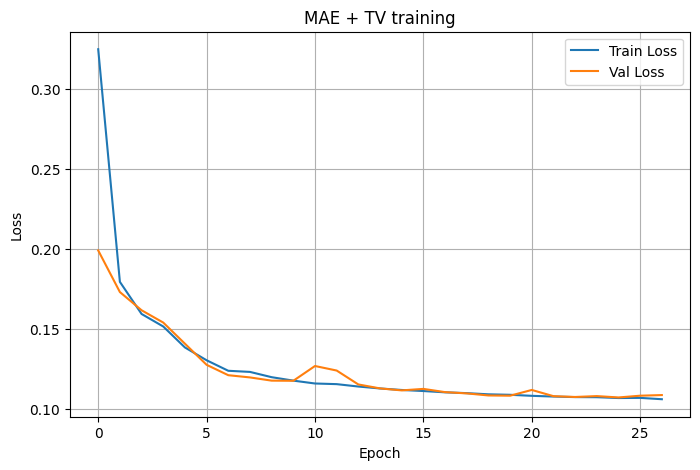

In [ ]:
plot_train_val_loss(history1, title="MAE + TV training")

TO load an old model pretrained

In [ ]:
model_snap_1 = build_unet_film_max(img_size=IMG_SIZE, base=BASE, sep=False)
model_snap_1.load_weights(CKPT_PATH)

See the results of the model

In [ ]:
# --- Esecuzione e stampa "pulita" ---
results = evaluate_on_test(model, test_lab)

mse_model_mean = results["mse_model_mean"]
mse_model_std  = results["mse_model_std"]

mse_base_mean  = results["mse_baseline_mean"]
mse_base_std   = results["mse_baseline_std"]

ratio_mean     = results["ratio_mean"]
ratio_std      = results["ratio_std"]

print("=== RISULTATI TEST ===")
print(f"MSE modello   : mean={mse_model_mean:.6f}  std={mse_model_std:.6f}")
print(f"MSE baseline  : mean={mse_base_mean:.6f}  std={mse_base_std:.6f}")
print(f"Rapporto (mod/baseline) : mean={ratio_mean:.6f}  std={ratio_std:.6f}")


=== RISULTATI TEST ===
MSE modello   : mean=0.009158  std=0.008571
MSE baseline  : mean=0.009577  std=0.007885
Rapporto (mod/baseline) : mean=1.054601  std=0.900377


Proceed with the second training of the same model using MSE

In [ ]:
opt_f2 = tf.keras.optimizers.AdamW(learning_rate=2e-4, weight_decay=1e-4, clipnorm=1.0)


model.compile(
    optimizer=opt_f2,
    loss=huber_tv_loss(delta=0.05, lambda_tv=5e-5),   # Fase 2: Huber + TV
    metrics=[tf.keras.metrics.MeanAbsoluteError(name='mae'),
             tf.keras.metrics.MeanSquaredError(name='mse')]
)

# --- Callback set per Fase 2 ---
callbacks_f2 = [
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_mse', mode='min',
        factor=0.5, patience=3, cooldown=2, min_lr=5e-6, verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor='val_mse', mode='min',
        patience=6,               # fisso (prima avevi phase==2 non definita)
        min_delta=1e-4,
        restore_best_weights=True,
        verbose=1
    ),
    tf.keras.callbacks.ModelCheckpoint(
        filepath=CKPT_PATH, monitor='val_mse',
        save_best_only=True, save_weights_only=True, mode='min', verbose=1
    )
]

# --- Train Fase 2 ---
history2 = model.fit(
    train_lab,
    validation_data=val_lab,
    epochs=100,
    callbacks=callbacks_f2,      # <-- usa il nome giusto
    verbose=1
)


Epoch 1/100
109/109 ━━━━━━━━━━━━━━━━━━━━ 0s 436ms/step - loss: 0.0094 - mae: 0.1194 - mse: 0.0275
Epoch 1: val_mse improved from inf to 0.03019, saving model to /content/drive/MyDrive/Colorizer/best_colorizer_film.weights.h5
109/109 ━━━━━━━━━━━━━━━━━━━━ 118s 615ms/step - loss: 0.0094 - mae: 0.1195 - mse: 0.0275 - val_loss: 0.0087 - val_mae: 0.1249 - val_mse: 0.0302 - learning_rate: 2.0000e-04
Epoch 2/100
109/109 ━━━━━━━━━━━━━━━━━━━━ 0s 191ms/step - loss: 0.0076 - mae: 0.1206 - mse: 0.0289
Epoch 2: val_mse improved from 0.03019 to 0.02955, saving model to /content/drive/MyDrive/Colorizer/best_colorizer_film.weights.h5
109/109 ━━━━━━━━━━━━━━━━━━━━ 32s 294ms/step - loss: 0.0076 - mae: 0.1206 - mse: 0.0289 - val_loss: 0.0074 - val_mae: 0.1234 - val_mse: 0.0296 - learning_rate: 2.0000e-04
Epoch 3/100
109/109 ━━━━━━━━━━━━━━━━━━━━ 0s 182ms/step - loss: 0.0070 - mae: 0.1212 - mse: 0.0293
Epoch 3: val_mse did not improve from 0.02955
109/109 ━━━━━━━━━━━━━━━━━━━━ 28s 253ms/step - loss: 0.0070 - 

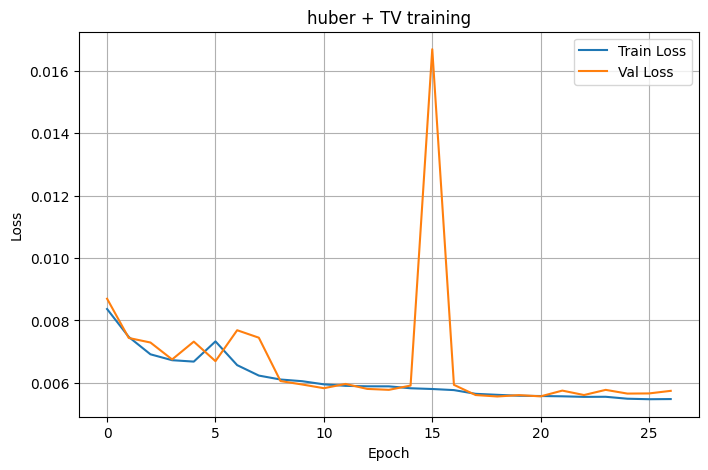

In [ ]:
plot_train_val_loss(history2, title="huber + TV training")

Rest:

In [ ]:
# --- Esecuzione e stampa "pulita" ---
results = evaluate_on_test(model, test_lab)

mse_model_mean = results["mse_model_mean"]
mse_model_std  = results["mse_model_std"]

mse_base_mean  = results["mse_baseline_mean"]
mse_base_std   = results["mse_baseline_std"]

ratio_mean     = results["ratio_mean"]
ratio_std      = results["ratio_std"]

print("=== RISULTATI TEST ===")
print(f"MSE modello   : mean={mse_model_mean:.6f}  std={mse_model_std:.6f}")
print(f"MSE baseline  : mean={mse_base_mean:.6f}  std={mse_base_std:.6f}")
print(f"Rapporto (mod/baseline) : mean={ratio_mean:.6f}  std={ratio_std:.6f}")


=== RISULTATI TEST ===
MSE modello   : mean=0.014513  std=0.010661
MSE baseline  : mean=0.009577  std=0.007885
Rapporto (mod/baseline) : mean=1.863584  std=5.590354


TO save this model

In [ ]:
model_snap_2 = build_unet_film_max(img_size=IMG_SIZE, base=BASE, sep=False)
model_snap_2.load_weights(CKPT_PATH)

Now proceed with the third training using pure MSE

In [ ]:
opt_f3 = tf.keras.optimizers.AdamW(learning_rate=1e-4, weight_decay=1e-4, clipnorm=1.0)
# opt_f3 = tf.keras.optimizers.Adam(learning_rate=1e-4, clipnorm=1.0)

# --- Compile ---
model.compile(
    optimizer=opt_f3,
    loss=mse_loss(),                               # Fase 3: MSE puro
    metrics=[tf.keras.metrics.MeanAbsoluteError(name='mae'),
             tf.keras.metrics.MeanSquaredError(name='mse')]
)

# --- Callback set per Fase 3 (più stretti) ---
callbacks_f3 = [
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_mse', mode='min',
        factor=0.5, patience=2, cooldown=1, min_lr=5e-6, verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor='val_mse', mode='min',
        patience=4,
        min_delta=1e-4,
        restore_best_weights=True,
        verbose=1
    ),
    tf.keras.callbacks.ModelCheckpoint(
        filepath=CKPT_PATH, monitor='val_mse',
        save_best_only=True, save_weights_only=True, mode='min', verbose=1
    )
]

# --- Train Fase 3 ---
history3 = model.fit(
    train_lab,
    validation_data=val_lab,
    epochs=30,                   # di solito poche epoche bastano
    callbacks=callbacks_f3,
    verbose=1
)

Epoch 1/30
109/109 ━━━━━━━━━━━━━━━━━━━━ 0s 433ms/step - loss: 0.0207 - mae: 0.1039 - mse: 0.0207
Epoch 1: val_mse improved from inf to 0.02385, saving model to /content/drive/MyDrive/Colorizer/best_colorizer_film.weights.h5
109/109 ━━━━━━━━━━━━━━━━━━━━ 115s 601ms/step - loss: 0.0207 - mae: 0.1039 - mse: 0.0207 - val_loss: 0.0238 - val_mae: 0.1175 - val_mse: 0.0238 - learning_rate: 1.0000e-04
Epoch 2/30
109/109 ━━━━━━━━━━━━━━━━━━━━ 0s 183ms/step - loss: 0.0171 - mae: 0.0932 - mse: 0.0171
Epoch 2: val_mse improved from 0.02385 to 0.01750, saving model to /content/drive/MyDrive/Colorizer/best_colorizer_film.weights.h5
109/109 ━━━━━━━━━━━━━━━━━━━━ 30s 275ms/step - loss: 0.0171 - mae: 0.0932 - mse: 0.0171 - val_loss: 0.0175 - val_mae: 0.0955 - val_mse: 0.0175 - learning_rate: 1.0000e-04
Epoch 3/30
109/109 ━━━━━━━━━━━━━━━━━━━━ 0s 188ms/step - loss: 0.0162 - mae: 0.0900 - mse: 0.0162
Epoch 3: val_mse improved from 0.01750 to 0.01673, saving model to /content/drive/MyDrive/Colorizer/best_color

In [ ]:
# --- Esecuzione e stampa "pulita" ---
results = evaluate_on_test(model, test_lab)

mse_model_mean = results["mse_model_mean"]
mse_model_std  = results["mse_model_std"]

mse_base_mean  = results["mse_baseline_mean"]
mse_base_std   = results["mse_baseline_std"]

ratio_mean     = results["ratio_mean"]
ratio_std      = results["ratio_std"]

print("=== RISULTATI TEST ===")
print(f"MSE modello   : mean={mse_model_mean:.6f}  std={mse_model_std:.6f}")
print(f"MSE baseline  : mean={mse_base_mean:.6f}  std={mse_base_std:.6f}")
print(f"Rapporto (mod/baseline) : mean={ratio_mean:.6f}  std={ratio_std:.6f}")

=== RISULTATI TEST ===
MSE modello   : mean=0.006784  std=0.005909
MSE baseline  : mean=0.009577  std=0.007885
Rapporto (mod/baseline) : mean=0.933994  std=4.848202


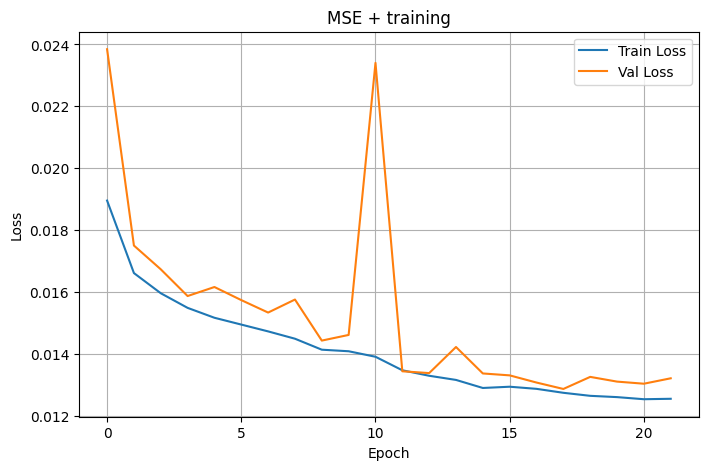

In [ ]:
plot_train_val_loss(history3, title="MSE + training")

In [ ]:
model_snap_3 = build_unet_film_max(img_size=IMG_SIZE, base=BASE, sep=False)
model_snap_3.load_weights(CKPT_PATH)